In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mspdetect as msp
import pandas as pd

from pathlib import Path

In [2]:
# extract the final MSE value for all patients
mse_arrays = {}
huber_arrays = {}

root = Path("../msp_pipeline/results/")
for f in root.iterdir():
    if f.is_dir():
        result = msp.load_result(f)
        mse_arrays[f"{f.name}"] = {}
        mse_arrays[f"{f.name}"]["final"] = []
        mse_arrays[f"{f.name}"]["best"] = result.best_start
        huber_arrays[f"{f.name}"] = {}
        huber_arrays[f"{f.name}"]["final"] = []
        for i in range(10):
            mse_arrays[f"{f.name}"][i] = result.starts[i].quadratic
            huber_arrays[f"{f.name}"][i] = result.starts[i].huber
            mse_arrays[f"{f.name}"]["final"].append(result.starts[i].quadratic[-1])
            huber_arrays[f"{f.name}"]["final"].append(result.starts[i].huber[-1])


In [3]:
def inlier_fraction(losses, rel_tol=0.05):
    losses = np.array(losses)
    min_loss = losses.min()
    threshold = min_loss * (1 + rel_tol)
    return (losses <= threshold).mean()

In [4]:
# extract relative difference and inlier fraction between lowest and highest
relative_differences = []
for patient_id, patient_dict in mse_arrays.items():
    relative_differences.append({
        "patient_id": patient_id,
        "diff": (max(patient_dict["final"]) - min(patient_dict["final"])) / min(patient_dict["final"]),
        "diff_start": (patient_dict["final"][0] - min(patient_dict["final"])) / min(patient_dict["final"]),
        "inlier_frac": inlier_fraction(patient_dict["final"])
    })

rel_diff = pd.DataFrame(relative_differences)

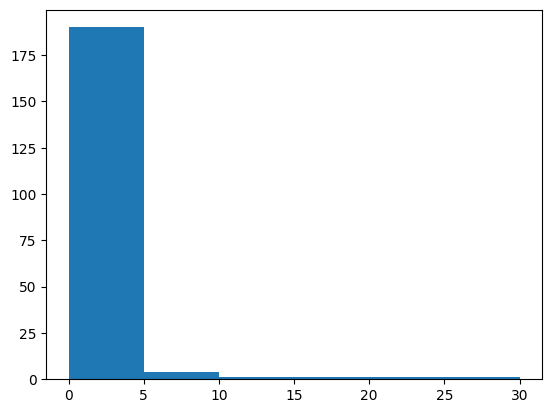

[190.   4.   1.   1.   1.   1.] [ 0.  5. 10. 15. 20. 25. 30.]


In [5]:
# relative difference between lowest and highest final value
plt.figure()
n, bins, patches = plt.hist(rel_diff["diff"] * 100, range = (0, 30), bins = 6)
plt.show()

print(n, bins)

In [6]:
# patients with a relative difference of larger than 5%
rel_diff.loc[rel_diff["diff"] > 0.05]

,patient_id,diff,diff_start,inlier_frac
9,2021-USZ-052,0.228019,9.874768e-04,0.9
27,2021-USZ-148,0.094007,2.512346e-04,0.9
29,2021-USZ-219,0.276357,3.696642e-05,0.9
113,2021-USZ-166,0.078405,3.494400e-05,0.7
120,2021-USZ-195,0.051966,5.196619e-02,0.6
125,2021-USZ-138,0.090058,3.638720e-07,0.9
140,2021-USZ-117,0.103574,3.859493e-04,0.9
180,2021-USZ-042,0.163567,1.867578e-04,0.9


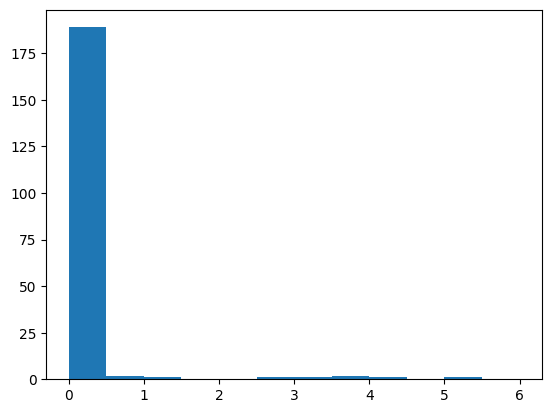

[189.   2.   1.   0.   0.   1.   1.   2.   1.   0.   1.   0.] [0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5 6. ]


In [7]:
# relative difference between lowest final value and best start

plt.figure()
n, bins, patches = plt.hist(rel_diff["diff_start"] * 100, range = (0, 6), bins = 12)
plt.show()

print(n, bins)

In [8]:
# patients with a relative difference between best final and best start of larger than 5%
rel_diff.loc[rel_diff["diff_start"] > 0.05]

,patient_id,diff,diff_start,inlier_frac
120,2021-USZ-195,0.051966,0.051966,0.6


In [9]:
metrics = pd.read_csv("../msp_pipeline/metrics/metrics.csv", header=[0])

diff_dmsp = []

for patient_id, group in metrics.groupby("case_id"):
    diff_dmsp.append({
        "patient_id": patient_id,
        "dmsp_0": group.loc[group["is_first_start"], "GTVp_distance_msp_mm"].item(),
        "dmsp_best": group.loc[group["is_best"], "GTVp_distance_msp_mm"].item(),
        "diff": group.loc[group["is_first_start"], "GTVp_distance_msp_mm"].item() - group.loc[group["is_best"], "GTVp_distance_msp_mm"].item(),
        "diff_max": group["GTVp_distance_msp_mm"].max() - group["GTVp_distance_msp_mm"].min()
    })
diff_dmsp = pd.DataFrame(diff_dmsp)

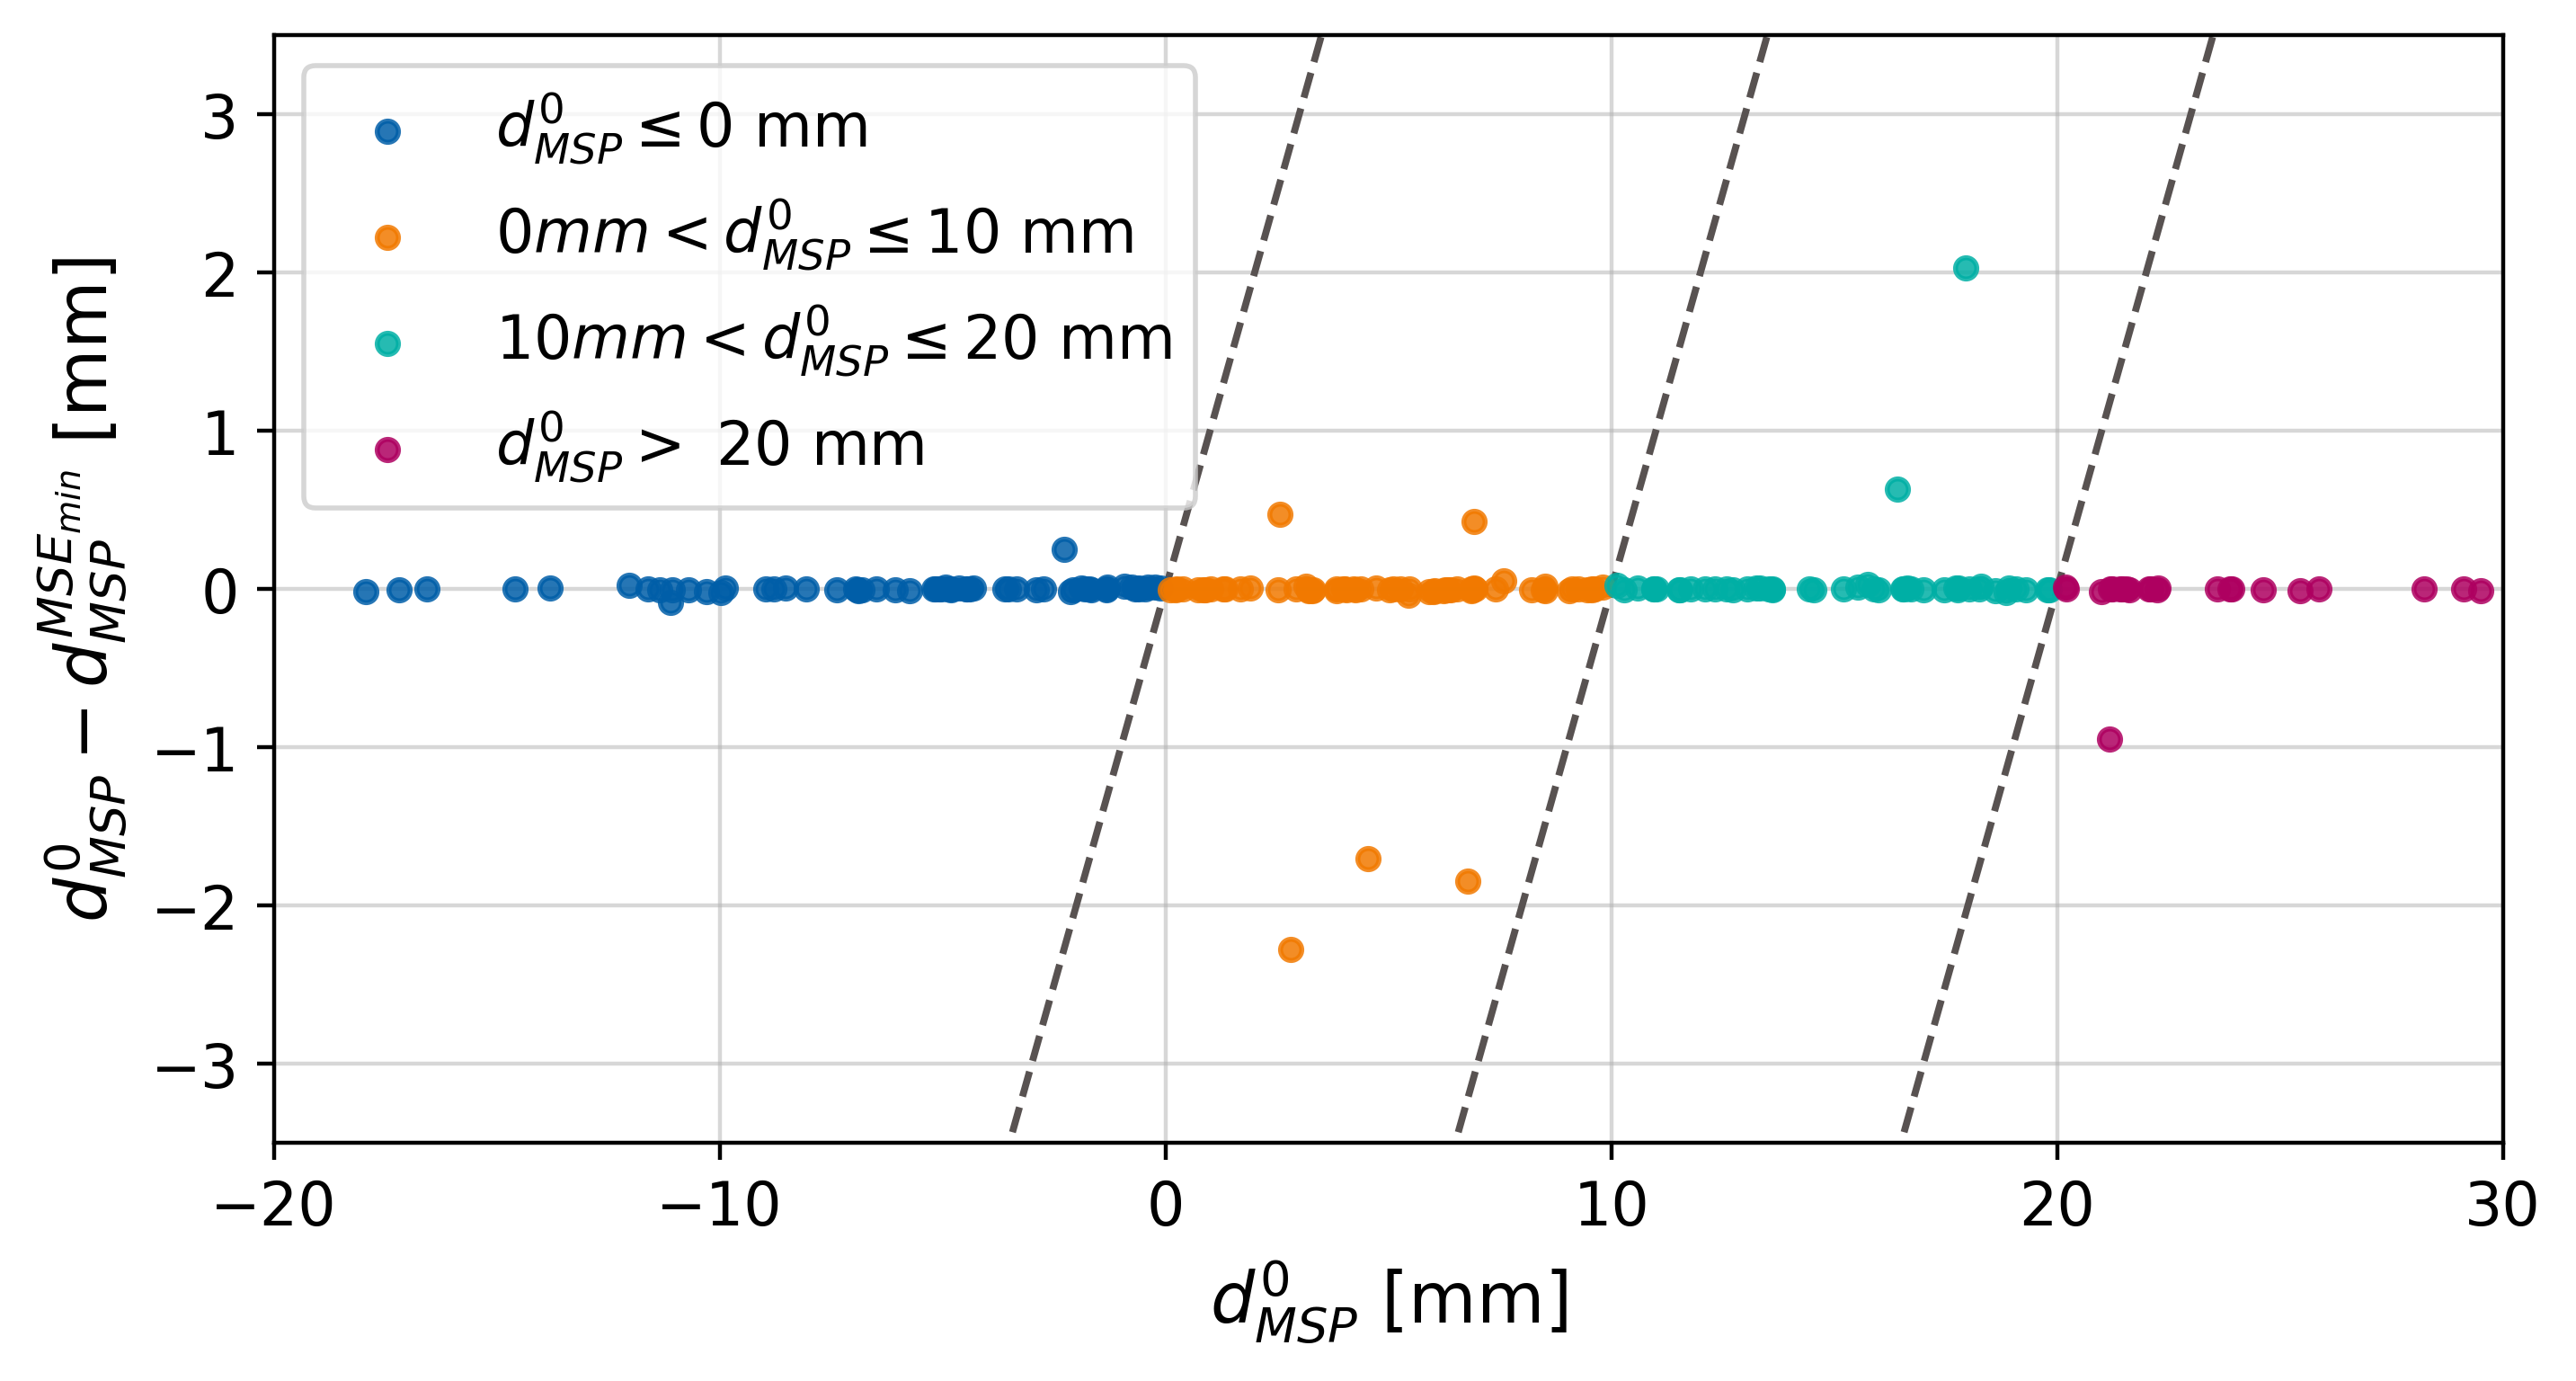

In [10]:
fig, ax = plt.subplots(figsize=(8, 4), dpi=400)

colors = ["#005ea8", "#f17900", "#00afa5", "#ae0060", "#c5d5db",]


x = diff_dmsp["dmsp_0"]
y = diff_dmsp["diff"]

idx1 = np.where(x < 0)[0]
idx2 = np.where((x >= 0) & (x < 10))[0]
idx3 = np.where((x >= 10) & (x < 20))[0]
idx4 = np.where(x >= 20)[0]
ax.scatter(x[idx1], y[idx1], color=colors[0], s=18, alpha=0.85, zorder=3, label=r"$d_{MSP}^0 \leq 0$ mm")
ax.scatter(x[idx2], y[idx2], color=colors[1], s=18, alpha=0.85, zorder=3, label=r"$0 mm < d_{MSP}^0 \leq 10$ mm")
ax.scatter(x[idx3], y[idx3], color=colors[2], s=18, alpha=0.85, zorder=3, label=r"$10 mm < d_{MSP}^0 \leq 20$ mm")
ax.scatter(x[idx4], y[idx4], color=colors[3], s=18, alpha=0.85, zorder=3, label=r"$d_{MSP}^0 >$ 20 mm")

x_line = np.linspace(-20, 30, 1000)
y0 = x_line
y1 = x_line - 10
y2 = x_line - 20

ax.set_xlim(-20, 30)
ax.set_ylim(-3.5, 3.5)
ymin, ymax = ax.get_ylim()

# Outer zones (everything above top line and below bottom line)
# ax.fill_between(x_line, y0, ymax, color="#e63946", alpha=0.25, zorder=1, label=r"$d_{MSP}$ < 0 mm")
# ax.fill_between(x_line, y0, y1, color="#f4a261", alpha=0.25, zorder=1, label=r"$0 mm < d_{MSP}$ < 10 mm")
# ax.fill_between(x_line, y1, y2, color="#2a9d8f", alpha=0.20, zorder=1, label=r"$10 mm < d_{MSP}$ < 20 mm")
# ax.fill_between(x_line, ymin, y2, color="#1d3557", alpha=0.25, zorder=1, label=r"$d_{MSP}$ > 20 mm")

ax.plot(x_line, y0, color="#585251", lw=1.4, linestyle='--')
ax.plot(x_line, y1, color="#585251", lw=1.4, linestyle='--')
ax.plot(x_line, y2, color="#585251", lw=1.4, linestyle='--')

ax.set_xlabel(r"$d_{MSP}^{0}$ [mm]", fontsize=14)
ax.set_ylabel(r"$d_{MSP}^{0} - d_{MSP}^{MSE_{min}}$ [mm]", fontsize=14)
ax.tick_params(labelsize=12)
ax.grid(alpha=0.5)
ax.legend(loc="upper left", fontsize=12)
plt.savefig('figures/msp_differences_multistart.pdf', bbox_inches='tight')
plt.show()

In [11]:
diff_dmsp.loc[abs(diff_dmsp["diff"]) > 0.1].sort_values("diff")

,patient_id,dmsp_0,dmsp_best,diff,diff_max
11,2021-USZ-023,2.814268,5.087939,-2.273671,2.273671
66,2021-USZ-098,6.774537,8.617377,-1.842841,1.850879
89,2021-USZ-121,4.548877,6.252362,-1.703485,1.723975
151,2021-USZ-195,21.175423,22.120159,-0.944735,0.952083
131,2021-USZ-172,-2.274971,-2.527343,0.252372,0.252372
181,2021-USZ-271,6.928104,6.499276,0.428827,0.436443
48,2021-USZ-071,2.563898,2.087368,0.476530,0.476530
147,2021-USZ-191,16.410163,15.776938,0.633225,0.667036
178,2021-USZ-268,17.946703,15.918312,2.028391,2.126200


In [12]:
rel_diff.loc[rel_diff["diff_start"] > 0.005].sort_values("patient_id")

,patient_id,diff,diff_start,inlier_frac
23,2021-USZ-023,0.036236,0.036236,1.0
188,2021-USZ-071,0.007069,0.007069,1.0
170,2021-USZ-098,0.035341,0.035341,1.0
1,2021-USZ-121,0.007187,0.007166,1.0
101,2021-USZ-172,0.029268,0.029268,1.0
66,2021-USZ-191,0.045823,0.042485,1.0
120,2021-USZ-195,0.051966,0.051966,0.6
25,2021-USZ-268,0.013662,0.013662,1.0
6,2021-USZ-271,0.031950,0.031409,1.0


In [13]:
diff_dmsp["diff_max"].max()

np.float64(4.29145592151923)

In [14]:
patient_id = "2021-USZ-023"
case = msp.load_case(
    f"/home/noemibuhrer/Datasets/OP_USZ/Patient_structures_clean_anonymised/{patient_id}",
    image="image",
    structures={"GTVp": "GTVp", "Body": "Body", "Mandible": "Mandible", "Spinal Cord": "Spinal Cord"},
)
result = msp.load_result(f"../msp_pipeline/results/{patient_id}")

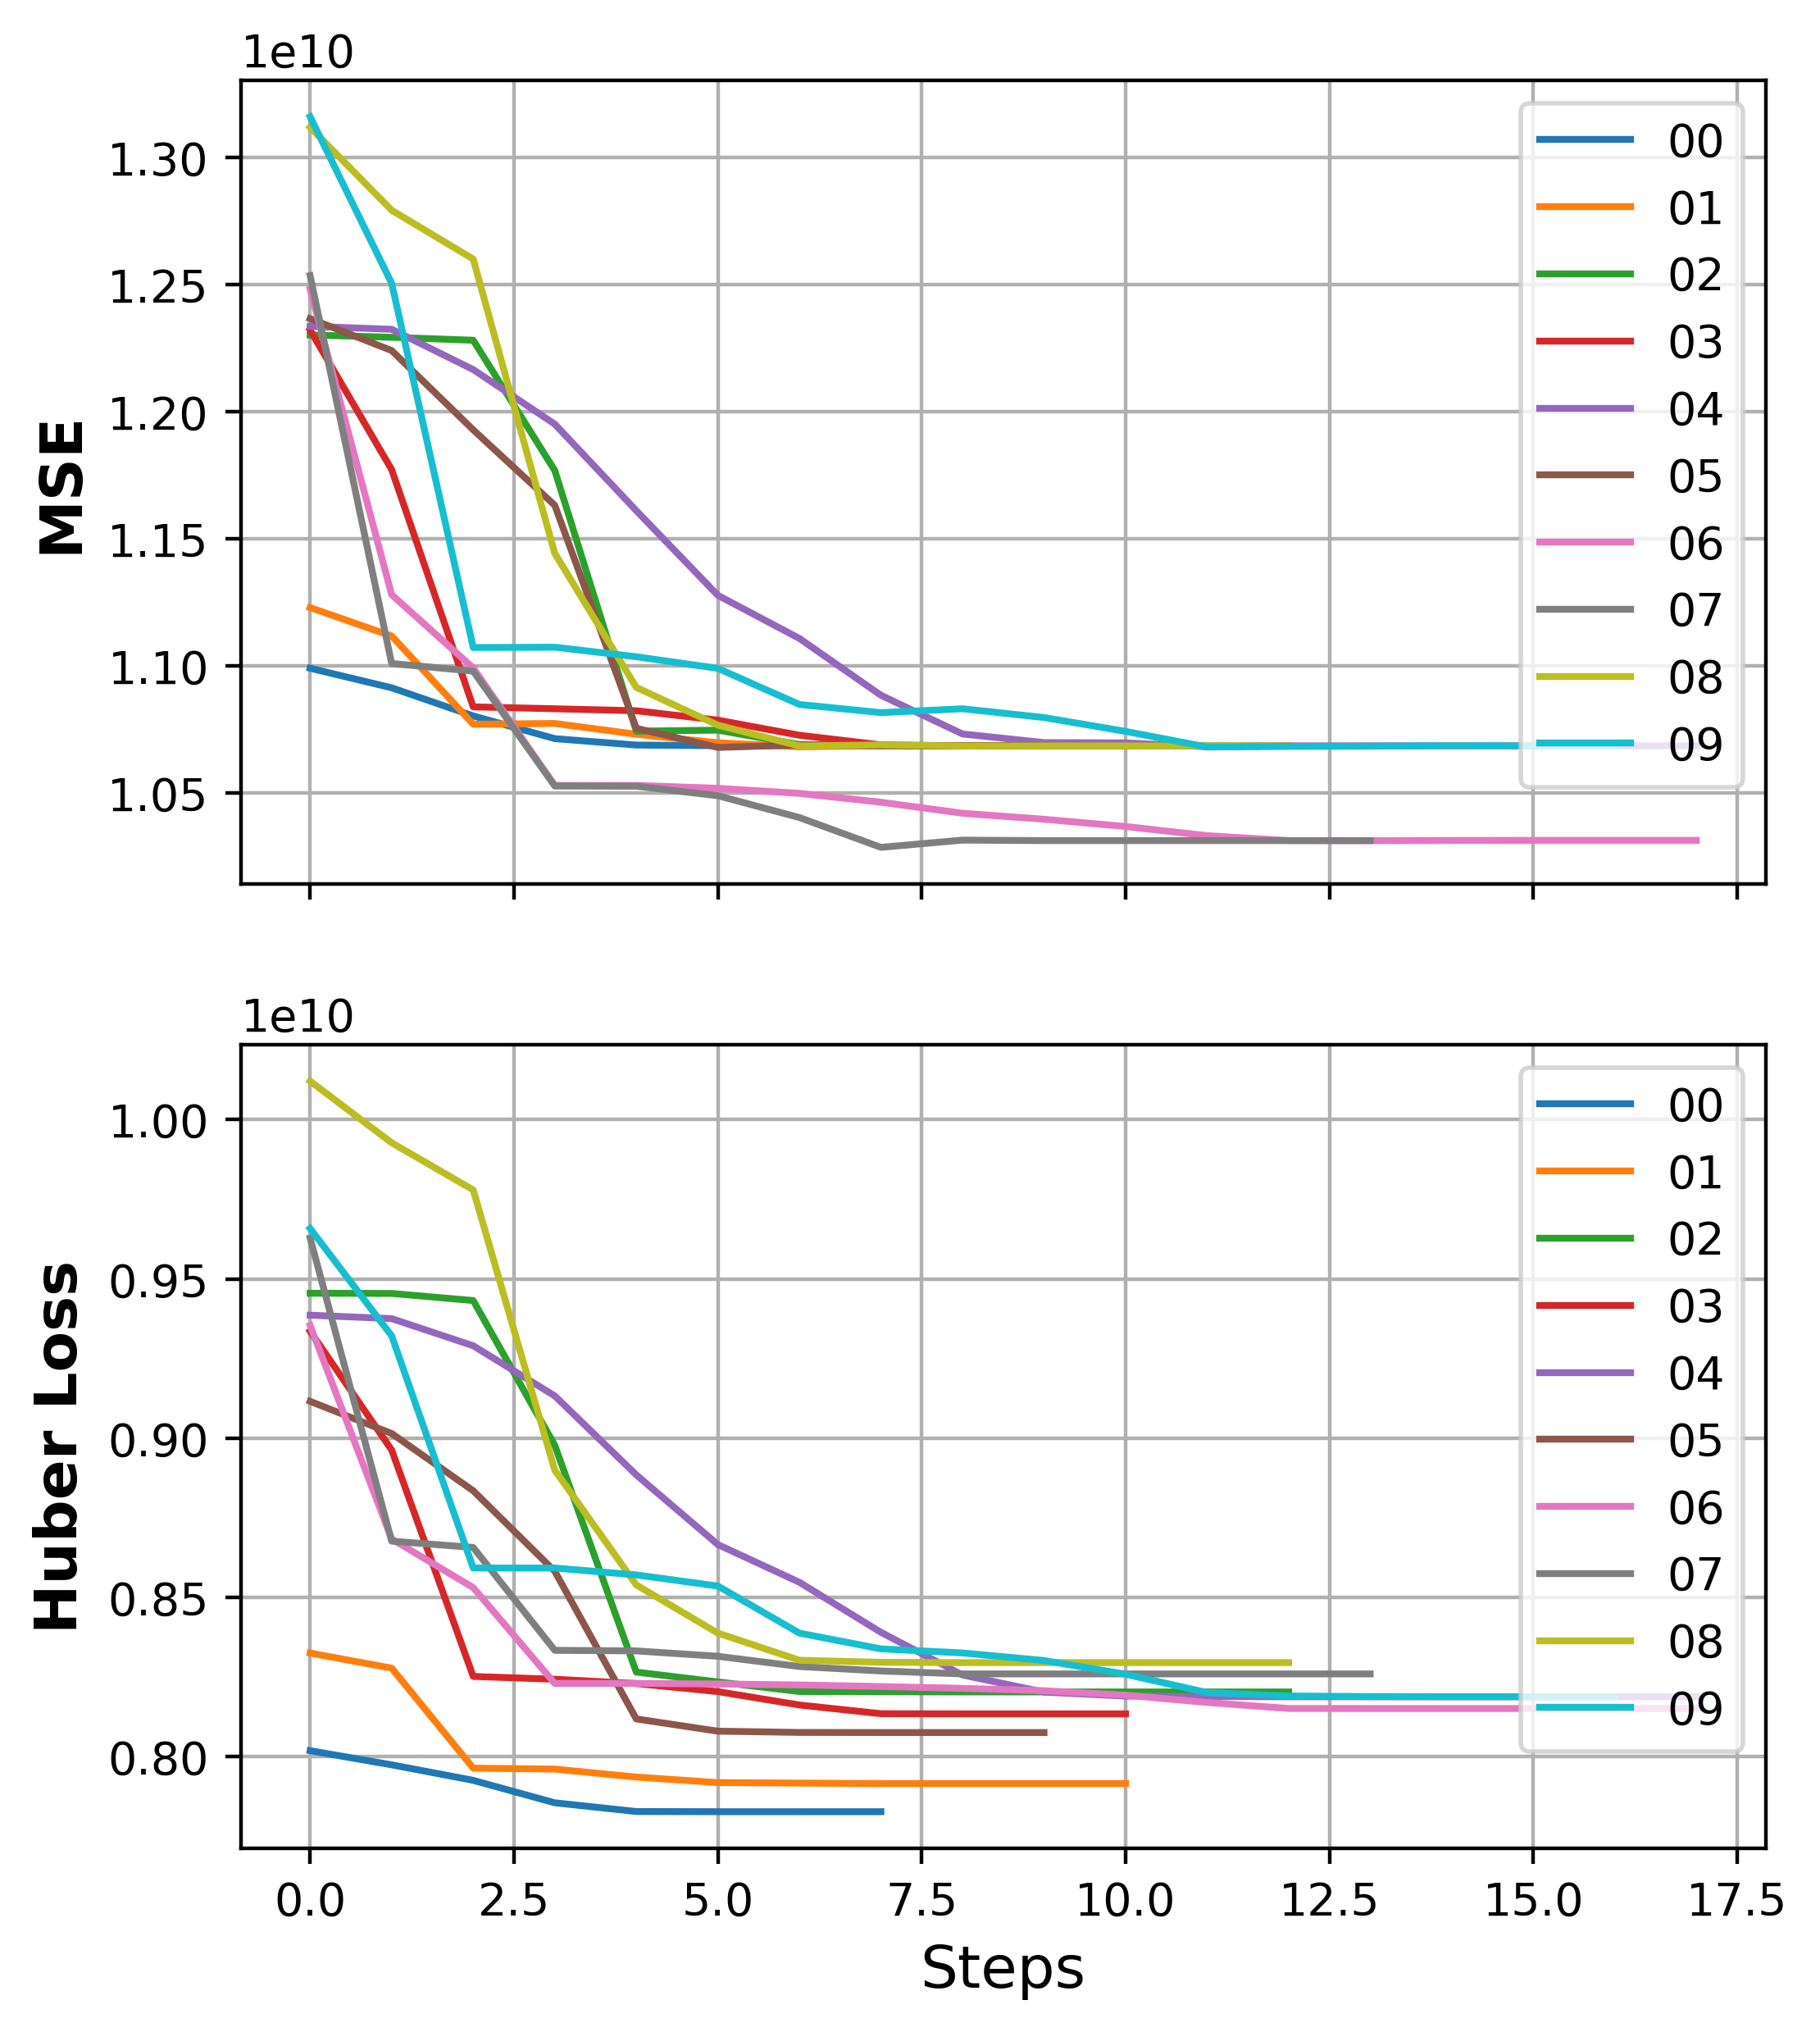

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(6, 7), dpi=400, sharex=True)
for i in range(10):
    f = f"{i:02d}"

    axes[1].plot(np.arange(len(result.starts[i].huber)), result.starts[i].huber, label = f"{f}")
    axes[0].plot(np.arange(len(result.starts[i].quadratic)), result.starts[i].quadratic, label = f"{f}")

axes[1].set_ylabel("Huber Loss", fontweight="bold", fontsize=13)
axes[0].set_ylabel("MSE", fontweight="bold", fontsize=13)
axes[1].set_xlabel("Steps", fontsize=13)
#axes[2].set_title("MSE w/o start point")
axes[0].legend()
axes[0].grid()
axes[1].legend()
axes[1].grid()
plt.savefig(f'figures/{patient_id}_optimisation.pdf', bbox_inches='tight')
plt.show()

In [17]:
from mspdetect.viz import viewer
candidate_planes = [*[result.starts[i].final for i in range(10) if i != result.best_start], result.plane]
plane_labels = [*[f"{i:02d}: {result.starts[i].final_quadratic:.2E}" for i in range(10) if i != result.best_start], f"best: {result.starts[result.best_start].final_quadratic:.2E}"]
viewer(case, candidate_planes, plane_labels)